# Pregunta 2 - Grupo 7

In [2]:
import numpy as np

## Inciso A
Calculamos la derivada de $\sigma$ con la definición de derivada, $\sigma'(t)=\frac{\sigma(t+h)-\sigma(t-h)}{2h}$


La comparamos con $\sigma(t)\big(1-\sigma(t)\big)$ en 20 valores de $t$ elegidos al azar


In [3]:
np.random.seed(0)
t = np.sort(np.random.uniform(-5, 5, 20))
h = 10**-5

sigma = 1 / (1 + np.exp(-t))
sigma_mas = 1 / (1 + np.exp(-(t + h)))
sigma_menos = 1 / (1 + np.exp(-(t - h)))
derivada = (sigma_mas - sigma_menos) / (2*h) 
formula = sigma * (1 - sigma) 

print("derivada:", derivada)
print("formula:", formula)

derivada: [0.00811335 0.01334154 0.01559729 0.18117456 0.21683859 0.22715163
 0.24485354 0.23782035 0.23567981 0.22315706 0.19408814 0.15304831
 0.09330626 0.0549262  0.04867493 0.03348035 0.02354219 0.01911825
 0.01378567 0.00950521]
formula: [0.00811335 0.01334154 0.01559729 0.18117456 0.21683859 0.22715163
 0.24485354 0.23782035 0.23567981 0.22315706 0.19408814 0.15304831
 0.09330626 0.0549262  0.04867493 0.03348035 0.02354219 0.01911825
 0.01378567 0.00950521]


La derivada y la fórmula dan el mismo valor en todos los puntos, por lo que la derivada satisface $\sigma'(t)=\sigma(t)\big(1-\sigma(t)\big)$. Además todos los valores de la derivada son positivos y ninguno supera $0.25$, tiendo una cota en $0<\sigma'(t)<1/4$

Para el máximo derivamos otra vez y vemos su signo

In [4]:
derivada_mas = sigma_mas * (1 - sigma_mas)
derivada_menos = sigma_menos * (1 - sigma_menos)
segunda = (derivada_mas - derivada_menos) / (2*h)
print("t:", np.round(t, 4))
print("segunda derivada:", np.round(segunda, 6))

t: [-4.7978 -4.2896 -4.1287 -1.1656 -0.7635 -0.6241  0.2889  0.4488  0.4881
  0.6804  1.0276  1.4589  2.1519  2.7816  2.9173  3.3262  3.7001  3.9177
  4.256   4.6366]
segunda derivada: [ 0.007981  0.012981  0.015103  0.095061  0.078974  0.068671 -0.035131
 -0.052492 -0.056406 -0.073123 -0.091787 -0.09531  -0.07387  -0.048519
 -0.04368  -0.031158 -0.022406 -0.018373 -0.0134   -0.009323]


La segunda derivada es positiva para todos los $t$ negativos, por lo que crece y negativa para todos los $t$ positivos, decreciendo, entonces cambia de signo en $t=0$ y ahí $\sigma'$ alcanza su máximo


Evaluamos la derivada en ese punto

In [5]:
t0 = 0
sigma0 = 1 / (1 + np.exp(-t0))
derivada0 = (1 / (1 + np.exp(-(t0 + h))) - 1 / (1 + np.exp(-(t0 - h)))) / (2*h)
print(np.round(derivada0, 6))

0.25


La derivada alcanza su máximo en $t=0$, donde vale 1/4

## Inciso B
Queremos calcular el gradiente en un punto cualquiera $\theta=(a_1,b_1,a_2,b_2,v,c)$ elegido al azar en $[-1,1]$ para un dato cualquiera $(x_i,y_i)$

In [6]:
np.random.seed(0)
theta = np.random.uniform(-1, 1, 6)
a1, b1, a2, b2, v, c = theta

x_i = np.random.uniform(-1, 1)
y_i = np.random.uniform(-1, 1)

print(theta)
print(x_i, y_i)

[ 0.09762701  0.43037873  0.20552675  0.08976637 -0.1526904   0.29178823]
-0.12482557747461498 0.7835460015641595


Pasamos el dato capa por capa
$$z_{1,i}=a_1x_i+b_1,\quad h_{1,i}=\sigma(z_{1,i}),\quad z_{2,i}=a_2h_{1,i}+b_2,\quad h_{2,i}=\sigma(z_{2,i}),\quad \hat y_i=c+v\,h_{2,i},\quad e_i=\hat y_i-y_i,\quad L_i=\tfrac12e_i^2$$

In [7]:
z1 = a1*x_i + b1 # capa 1
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2 # capa 2
h2 = 1 / (1 + np.exp(-z2))
y_gorro = c + v*h2# capa salida
e = y_gorro - y_i
L = e**2 / 2

print("z1 =", z1, "  h1 =", h1)
print("z2 =", z2, "  h2 =", h2)
print("y_gorro =", y_gorro, "  e =", e, "  L =", L)

z1 = 0.41819238511226353   h1 = 0.6030506226898621
z2 = 0.21370940185322834   h2 = 0.5532249316963992
y_gorro = 0.2073160892911476   e = -0.5762299122730119   L = 0.1660204558990815


Usamos la regla de la cadena y definicion de la derivada para cada capa y las multiplicamos. Como muchos pasos se repiten, cada uno se calcula una sola vez

Elegimos un h pequeño y fijo. Partimos por la perdida $L_i=\tfrac12e_i^2$ y el error $e_i=\hat y_i-y_i$

In [8]:
h = 10**-5
derivadaLi_de = ((e + h)**2 / 2 - (e - h)**2 / 2) / (2*h)
derivadaError_dy = ((y_gorro + h - y_i) - (y_gorro - h - y_i)) / (2*h) # e= y_gorro - y_i
print(derivadaLi_de)
print(derivadaError_dy)

-0.5762299122705206
1.000000000001


Capa de salida $\hat y_i=c+v\,h_{2,i}$

In [9]:
derivadaY_dc  = ((c + h + v*h2) - (c - h + v*h2))/ (2*h)
derivadaY_dv  = ((c + (v + h)*h2) - (c + (v - h)*h2))/ (2*h)
derivadaY_dh2 = ((c + v*(h2 + h)) - (c + v*(h2 - h))) / (2*h)
print(derivadaY_dc)
print(derivadaY_dv)
print(derivadaY_dh2)

1.000000000001
0.5532249316958504
-0.1526904013213204


Capa oculta 2 $h_{2,i}=\sigma(z_{2,i})$

In [10]:
derivadaH2_dz2 = (1 / (1 + np.exp(-(z2 + h))) - 1 / (1 + np.exp(-(z2 - h)))) / (2*h)

derivadaZ2_db2 = ((a2*h1 + b2 + h) - (a2*h1 + b2 - h)) / (2*h)
derivadaZ2_da2 = (((a2 + h)*h1 + b2) - ((a2 - h)*h1 + b2)) / (2*h)
derivadaZ2_dh1 = ((a2*(h1 + h) + b2) - (a2*(h1 - h) + b2)) / (2*h)

print(derivadaH2_dz2)
print(derivadaZ2_db2)
print(derivadaZ2_da2)
print(derivadaZ2_dh1)

0.24716710664285377
1.000000000001
0.6030506226897825
0.20552675214224878


Capa oculta 1 $h_{1,i}=\sigma(z_{1,i})$

In [11]:
derivadaH1_dz1 = (1 / (1 + np.exp(-(z1 + h))) - 1 / (1 + np.exp(-(z1 - h)))) / (2*h)

derivadaZ1_db1 = ((a1*x_i + b1 + h) - (a1*x_i + b1 - h)) / (2*h)
derivadaZ1_da1 = (((a1 + h)*x_i + b1) - ((a1 - h)*x_i + b1)) / (2*h)
print(derivadaH1_dz1)
print(derivadaZ1_db1)
print(derivadaZ1_da1)

0.2393805691613959
1.000000000001
-0.1248255774743967


- salida, $\;c \to \hat y_i \to e_i \to L_i$  y $\;v \to \hat y_i \to e_i \to L_i$
- capa oculta 2, $\;b_2 \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$ y $\;a_2 \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$
- capa oculta 1, $\;b_1 \to z_{1,i} \to h_{1,i} \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$  y $\;a_1 \to z_{1,i} \to h_{1,i} \to z_{2,i} \to h_{2,i} \to \hat y_i \to e_i \to L_i$ 

In [12]:
derivadaLi_dc = derivadaLi_de * derivadaError_dy * derivadaY_dc # salida
derivadaLi_dv = derivadaLi_de * derivadaError_dy * derivadaY_dv
print("derivadaLi dc =", derivadaLi_dc, "deriadaLi dv =", derivadaLi_dv)

derivadaLi_db2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_db2 # capa 2
derivadaLi_da2 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_da2
print("derivadaLi db2 =", derivadaLi_db2, "derivadaLi da2 =", derivadaLi_da2)

derivadaLi_db1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_db1 #capa 1
derivadaLi_da1 = derivadaLi_de * derivadaError_dy * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_da1
print("derivadaLi db1 =", derivadaLi_db1, "derivadaLi da1 =", derivadaLi_da1)



derivadaLi dc = -0.5762299122716732 deriadaLi dv = -0.31878475385728344
derivadaLi db2 = 0.021746942650486285 derivadaLi da2 = 0.013114507306961627
derivadaLi db1 = 0.0010699302433212737 derivadaLi da1 = -0.00013355466047976618


Juntamos las seis derivadas en el gradiente, en el orden $\theta=(a_1,b_1,a_2,b_2,v,c)$

In [13]:
gradiente = np.array([derivadaLi_da1, derivadaLi_db1, derivadaLi_da2, derivadaLi_db2, derivadaLi_dv, derivadaLi_dc])
print(gradiente)

[-1.33554660e-04  1.06993024e-03  1.31145073e-02  2.17469427e-02
 -3.18784754e-01 -5.76229912e-01]


Obtenemos el gradiente de la pérdida $L_i$ de un dato

## Inciso C

Cargamos los 200 pares $(x_i, y_i)$.


In [14]:
import numpy as np
import pandas as pd

df = pd.read_csv("datos/datos_P2.csv")
x = df["x"].to_numpy()
y = df["y"].to_numpy()
N = len(x)
print("N =", N)
print("x[0:5] =", np.round(x[:5], 4))
print("y[0:5] =", np.round(y[:5], 4))

N = 200
x[0:5] = [-7.830e-02  5.541e-01  4.000e-04 -1.749e-01  5.690e-02]
y[0:5] = [0.9378 0.0584 0.7272 1.0506 0.5781]


Definimos $J(\theta)=\frac{1}{2N}\sum_{i=1}^{N} e_i^2$ con $e_i=\hat{y}_i - y_i$. Paso capa por capa $z_{1,i}=a_1 x_i + b_1$, $h_{1,i}=\sigma(z_{1,i})$, $z_{2,i}=a_2 h_{1,i} + b_2$, $h_{2,i}=\sigma(z_{2,i})$, $\hat{y}_i=c+v h_{2,i}$.


In [15]:
def J(theta):
    a1, b1, a2, b2, v, c = theta
    s = 0.0
    for i in range(N):
        z1 = a1*x[i] + b1
        h1 = 1 / (1 + np.exp(-z1))
        z2 = a2*h1 + b2
        h2 = 1 / (1 + np.exp(-z2))
        y_gorro = c + v*h2
        e = y_gorro - y[i]
        s += e**2 / 2
    return s / N

Definimos gradiente $\nabla_{\theta} J$ por regla de la cadena. Cada derivada con definición $f'(u)=\frac{f(u+h)-f(u-h)}{2h}$ con $h=10^{-5}$, igual que en B. Se promedia sobre los $N$ datos: $\frac{\partial J}{\partial \theta^{(j)}}=\frac{1}{N}\sum_{i=1}^{N}\frac{\partial L_i}{\partial \theta^{(j)}}$.


In [16]:
def grad_J(theta):
    a1, b1, a2, b2, v, c = theta
    h = 10**-5
    grad = np.zeros(6)
    for i in range(N):
        z1 = a1*x[i] + b1
        h1 = 1 / (1 + np.exp(-z1))
        z2 = a2*h1 + b2
        h2 = 1 / (1 + np.exp(-z2))
        y_gorro = c + v*h2
        e = y_gorro - y[i]
        # derivadas por definicion, igual que las de la sofi
        derivadaLi_de = ((e + h)**2 / 2 - (e - h)**2 / 2) / (2*h)
        derivadaY_dc = ((c + h + v*h2) - (c - h + v*h2)) / (2*h)
        derivadaY_dv = ((c + (v + h)*h2) - (c + (v - h)*h2)) / (2*h)
        derivadaY_dh2 = ((c + v*(h2 + h)) - (c + v*(h2 - h))) / (2*h)
        derivadaH2_dz2 = (1/(1+np.exp(-(z2+h))) - 1/(1+np.exp(-(z2-h)))) / (2*h)
        derivadaZ2_db2 = ((a2*h1 + b2 + h) - (a2*h1 + b2 - h)) / (2*h)
        derivadaZ2_da2 = (((a2 + h)*h1 + b2) - ((a2 - h)*h1 + b2)) / (2*h)
        derivadaZ2_dh1 = ((a2*(h1 + h) + b2) - (a2*(h1 - h) + b2)) / (2*h)
        derivadaH1_dz1 = (1/(1+np.exp(-(z1+h))) - 1/(1+np.exp(-(z1-h)))) / (2*h)
        derivadaZ1_db1 = ((a1*x[i] + b1 + h) - (a1*x[i] + b1 - h)) / (2*h)
        derivadaZ1_da1 = (((a1 + h)*x[i] + b1) - ((a1 - h)*x[i] + b1)) / (2*h)

        ddc = derivadaLi_de * derivadaY_dc
        ddv = derivadaLi_de * derivadaY_dv
        ddb2 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_db2
        dda2 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_da2
        ddb1 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_db1
        dda1 = derivadaLi_de * derivadaY_dh2 * derivadaH2_dz2 * derivadaZ2_dh1 * derivadaH1_dz1 * derivadaZ1_da1
        grad[0] += dda1
        grad[1] += ddb1
        grad[2] += dda2
        grad[3] += ddb2
        grad[4] += ddv
        grad[5] += ddc
    return grad / N

Inicializamos $\theta_0 \sim U[-1,1]$ con `np.random.seed(0)` y verificamos por diferencias centradas $D_j=\frac{J(\theta_0+h e_j)-J(\theta_0-h e_j)}{2h}$ con $h=10^{-5}$.


In [17]:
np.random.seed(0)
theta0 = np.random.uniform(-1, 1, 6)
print("theta0 =", np.round(theta0, 6))
print("J(theta0) =", J(theta0))
g0 = grad_J(theta0)
print("grad_J(theta0) =", np.round(g0, 6))

h = 10**-5
D = np.zeros(6)
for j in range(6):
    ej = np.zeros(6); ej[j] = 1
    D[j] = (J(theta0 + h*ej) - J(theta0 - h*ej)) / (2*h)
print("Dj =", np.round(D, 6))
print("error |grad-Dj| =", np.round(np.abs(g0 - D), 10))
E = np.max(np.abs(g0 - D))
print("E = max |grad-Dj| =", E)

theta0 = [ 0.097627  0.430379  0.205527  0.089766 -0.15269   0.291788]
J(theta0) = 0.603522343354513
grad_J(theta0) = [-0.000862  0.001382  0.016455  0.027827 -0.407364 -0.737138]
Dj = [-0.000862  0.001382  0.016455  0.027827 -0.407364 -0.737138]
error |grad-Dj| = [0. 0. 0. 0. 0. 0.]
E = max |grad-Dj| = 1.6535790098304304e-11


## Inciso D

Descenso $\theta_{k+1}=\theta_k - \alpha \nabla J(\theta_k)$ con paso fijo $\alpha=1$ partiendo del mismo $\theta_0$ de C, por $20000$ iteraciones.


In [18]:
import matplotlib.pyplot as plt

alpha = 1.0
max_iter = 20000
theta = theta0.copy()
hist_J = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - alpha * g
    hist_J[k] = J(theta)

print("theta0 =", np.round(theta0,6))
print("theta20000 =", np.round(theta,6))
print("J(theta0) =", J(theta0))
print("J(theta20000) =", hist_J[-1])

theta0 = [ 0.097627  0.430379  0.205527  0.089766 -0.15269   0.291788]
theta20000 = [-4.366759 -0.747365  3.555817 -1.627432  2.960878 -0.439813]
J(theta0) = 0.603522343354513
J(theta20000) = 0.001373561381572392


Graficamos la evolución del error $J(\theta_k)$.


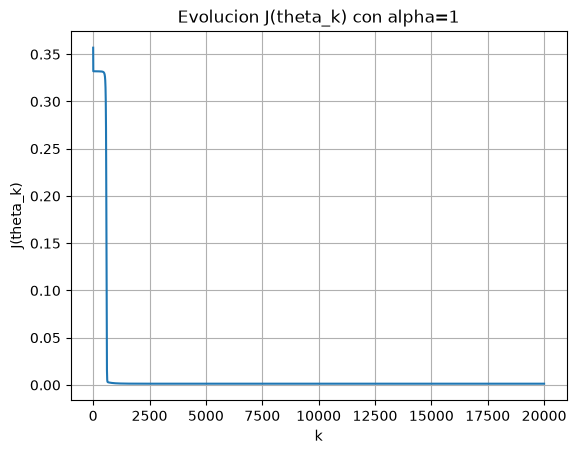

In [19]:
plt.figure()
plt.plot(hist_J)
plt.xlabel("k")
plt.ylabel("J(theta_k)")
plt.title("Evolucion J(theta_k) con alpha=1")
plt.grid(True)
plt.show()

Notamos una caída brusca del gradiente antes de las primeras 2500 iteraciones, estas son las que más reducen el error. Luego, se aprecia una caída lenta.

## Inciso E
Obtenemos los 6 parámetros finales de la red, $\theta_{20.000}=(a_1,b_1,a_2,b_2,v,c)$ y el valor de la pérdida

In [20]:
a1, b1, a2, b2, v, c = theta 
print("capa 1: a1 =", a1, ",b1 =", b1)
print("capa 2: a2 =", a2, ",b2 =", b2)
print("salida: v =", v, ",c =", c)
print("perdida =", J(theta))

capa 1: a1 = -4.366758916139333 ,b1 = -0.7473648017493512
capa 2: a2 = 3.5558165161029365 ,b2 = -1.62743181581607
salida: v = 2.960878308189766 ,c = -0.43981266258598267
perdida = 0.001373561381572392


Notamos que los parametros que multiplican $a_1<0$, $a_2>0$ y $v>0$, por regla de signos la salida de la red decrece. Ademas la perdida final se redujo

Calculamos la salida de la red en cada uno de los 100 valores de $x$ que creamos entre [-1, 1], capa por capa

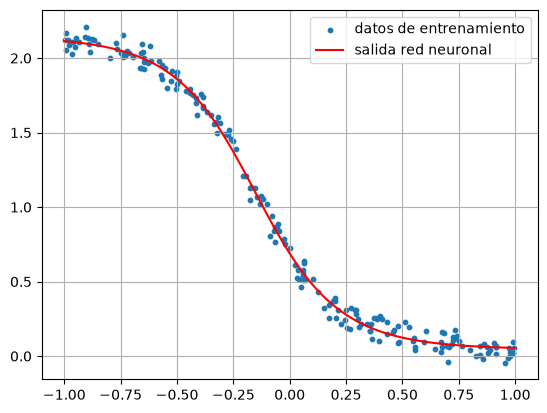

In [21]:
x_curva = np.linspace(-1, 1, 100) 
z1 = a1*x_curva + b1 
h1 = 1 / (1 + np.exp(-z1))
z2 = a2*h1 + b2 
h2 = 1 / (1 + np.exp(-z2))
y_curva = c + v*h2 

plt.figure()
plt.scatter(x, y, s=10, label="datos de entrenamiento") # columnas csv
plt.plot(x_curva, y_curva, color="red", label="salida red neuronal")
plt.legend()
plt.grid(True)
plt.show()

Notamos que la curva de la red sigue la forma de los datos y pasa entre los puntos, por lo que la red logró ajustarse a ellos

## Inciso F
### Parte i.
Para comparar como baja el error con cada paso, mostramos la perdida y el error en las iteraciones 1, 500, 10000 y 20000

In [27]:
alpha = 0.01
max_iter = 20000
theta = theta0.copy()
hist_J001 = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - alpha * g
    hist_J001[k] = J(theta)

print("1:", hist_J001[0]) # iteracion k
print("500:", hist_J001[499])
print("10000:", hist_J001[9999])
print("20000:", hist_J001[-1])

1: 0.596465422897854
500: 0.33200199905732114
10000: 0.33193505405534396
20000: 0.33188865121478256


In [23]:
alpha = 0.1
max_iter = 20000
theta = theta0.copy()
hist_J01 = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - alpha * g
    hist_J01[k] = J(theta)

print("1:", hist_J01[0])
print("500:", hist_J01[499])
print("10000:", hist_J01[9999])
print("20000:", hist_J01[-1])

1: 0.5371563891740073
500: 0.33196255073548053
10000: 0.0017430827807612154
20000: 0.0013912641368709075


In [24]:
# vicho, repito lo tuyo de la d
alpha = 1.0
max_iter = 20000
theta = theta0.copy()
hist_J1 = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - alpha * g
    hist_J1[k] = J(theta)

print("1:", hist_J1[0])
print("500:", hist_J1[499])
print("10000:", hist_J1[9999])
print("20000:", hist_J1[-1])

1: 0.3569206523049593
500: 0.3294419314367054
10000: 0.0013747217008035235
20000: 0.001373561381572392


In [ ]:
alpha = 2.5
max_iter = 20000
theta = theta0.copy()
hist_J25 = np.zeros(max_iter)

for k in range(max_iter):
    g = grad_J(theta)
    theta = theta - alpha * g
    hist_J25[k] = J(theta)

print("1:", hist_J25[0])
print("500:", round(hist_J25[499]))
print("10000:", round(hist_J25[9999]))
print("20000:", round(hist_J25[-1]))

1: 1.69179105043178
500: 56097803145881029967872
10000: 56097803145881029967872
20000: 56097803145881029967872


- $\alpha=0.01$: el error da un salto al inicio, pero pequeño y después casi no cambia entre 10.000 y 20.000, en las iteraciones el número es casi el mismo, entonces con un alfa muy pequeño no hay mucha variación
- $\alpha=0.1$:el inicio es similar al anterior, pero luego el cambio es más significativo y se nota un descenso evidente del error
- $\alpha=1$: el error parte más bajo que en los anteriores y el resultado final es muy similar al de $\alpha=0.1$
- $\alpha=2.5$: las diferencias son mucho más significativas, pero no hay descenso, el error crece

En conclusión, con un alpha muy pequeño el error casi no baja y con un alpha muy grande el error aumenta en vez de disminuir. El mejor alpha es 1, ya que desde la primera iteración el error es más pequeño que con los otros alphas y luego decrece de forma notoria hasta llegar al menor error

### Parte ii.
Partimos de 10 $\theta_0$ distintos con componentes al azar en $[-1,1]$ y otros 10 en $[-5,5]$ y anotamos el error final de cada uno


Por inciso b, el gradiente se multiplica por $\sigma'(z_1)=h_1(1-h_1)$ y $\sigma'(z_2)=h_2(1-h_2)$ y calculamos su promedio al inicio

In [31]:
np.random.seed(1)
alpha = 1.0
max_iter = 20000
J1 = np.zeros(10)

for i in range(10):
    thetaO0 = np.random.uniform(-1, 1, 6)
    theta = thetaO0.copy()
    a1, b1, a2, b2, v, c = thetaO0
    h1 = 1 / (1 + np.exp(-(a1*x + b1))) #capa 1
    h2 = 1 / (1 + np.exp(-(a2*h1 + b2))) # capa 2
    oz1 = np.mean(h1*(1 - h1))
    oz2 = np.mean(h2*(1 - h2))
    for k in range(max_iter): # descenso y dif
        g = grad_J(theta)
        theta = theta - alpha * g

    J1[i] = J(theta) 
    print(i + 1, " Jo0:", J(thetaO0),
          "J:", J1[i],
          "o'(z1):", oz1,
          "o'(z2):", oz2)

1  Jo0: 2.229310899271487 J: 0.0013753007606708018 o'(z1): 0.23775630980931808 o'(z2): 0.19629478335343076
2  Jo0: 0.5454486709414047 J: 0.0013752203865066716 o'(z1): 0.23671332518298505 o'(z2): 0.2499725857033337
3  Jo0: 0.7324867209187328 J: 0.0013728430126302598 o'(z1): 0.21341416854707507 o'(z2): 0.24424278925479825
4  Jo0: 0.6905713710442687 J: 0.0013751032935093892 o'(z1): 0.22122792140720043 o'(z2): 0.18237707013670193
5  Jo0: 0.3861695977166159 J: 0.0013806764344295118 o'(z1): 0.20884471273904395 o'(z2): 0.150492395007223
6  Jo0: 0.9029849898217015 J: 0.0013739110030641256 o'(z1): 0.23572689105636158 o'(z2): 0.23504039014683628
7  Jo0: 0.32302070368103086 J: 0.0013763149799730654 o'(z1): 0.22215001598623385 o'(z2): 0.24872584019443222
8  Jo0: 0.9108043049970022 J: 0.001378932219305392 o'(z1): 0.22728723301364528 o'(z2): 0.22795168106196553
9  Jo0: 1.784965357556342 J: 0.0013742105600920865 o'(z1): 0.21658793856017428 o'(z2): 0.24970503817490022
10  Jo0: 0.44913241249373287 J: 0

In [ ]:
J5 = np.zeros(10)
for i in range(10):
    thetaO0 = np.random.uniform(-5, 5, 6)
    theta = thetaO0.copy()
    a1, b1, a2, b2, v, c = thetaO0
    h1 = 1 / (1 + np.exp(-(a1*x + b1)))
    h2 = 1 / (1 + np.exp(-(a2*h1 + b2)))
    oz1 = np.mean(h1*(1 - h1))
    oz2 = np.mean(h2*(1 - h2))
    for k in range(max_iter):
        g = grad_J(theta)
        theta = theta - alpha * g

    J5[i] = J(theta) # error final
    print(i + 1, " Jo0:", round(J(thetaO0), 4),
          "J:", J5[i],
          "o'(z1):", oz1,
          "o'(z2):", oz2)

1  Jo0: 4.9395 J: 0.001396160133009028 o'(z1): 0.11876400873450872 o'(z2): 0.22382764949226108
2  Jo0: 0.7724 J: 0.001405916229991759 o'(z1): 0.2042870310052973 o'(z2): 0.04960971729883719
3  Jo0: 3.2292 J: 0.001402656806005092 o'(z1): 0.08663921817869964 o'(z2): 0.014457996213684845
4  Jo0: 0.3516 J: 0.331927389846129 o'(z1): 0.11061429228502696 o'(z2): 0.014218431213269187
5  Jo0: 2.0927 J: 0.33189428766799894 o'(z1): 0.035053998188120494 o'(z2): 0.018418443273010406
6  Jo0: 8.7501 J: 0.0013837496061716184 o'(z1): 0.04613244868843949 o'(z2): 0.24389980057436303
7  Jo0: 1.426 J: 0.0013629577983495869 o'(z1): 0.11783780252023329 o'(z2): 0.12078208870482023
8  Jo0: 0.5313 J: 0.0014120280642523435 o'(z1): 0.11652104138454245 o'(z2): 0.09420384902770387
9  Jo0: 0.8604 J: 0.0013995229160216902 o'(z1): 0.011593956390504192 o'(z2): 0.0010409248300767152
10  Jo0: 3.6891 J: 0.0013903341928117915 o'(z1): 0.09591287376510932 o'(z2): 0.0027379501959684327


In [36]:
print("promedio j1:", np.mean(J1), "promedio J5:", np.mean(J5))
print("j5 > J1:", np.mean(J5) > np.mean(J1))
print("j5/j1", np.mean(J5) / np.mean(J1))

print("mediana J1:", np.median(J1), "  mediana J5:", np.median(J5))
print("J5 > J1:", np.median(J5) > np.median(J1))
print("J5/j1", np.median(J5) / np.median(J1))

print("cantidad J < 0.01:  J1:", np.sum(J1 < 0.01), "  J5:", np.sum(J5 < 0.01)) #bajo error

promedio j1: 0.001375497946301409 promedio J5: 0.06749750032607409
j5 > J1: True
j5/j1 49.071320322628495
mediana J1: 0.0013751618400080303   mediana J5: 0.0014010898610133911
J5 > J1: True
J5/j1 1.0188545233375654
cantidad J < 0.01:  J1: 10   J5: 8


- El valor de J final no siempre es el mismo, J1 y J5 son diferentes e incluso dentro de cada rango las inicializaciones no repiten. En J5 además, dos inicializaciones terminan cerca de 0.33, muy lejos del resto, por eso el promedio de J5 es 49 veces el de J1, aunque sus medianas son casi iguales y en J1 los 10 llegan a $J<0.01$ mientras que en J5 solo 8
- En el inciso A vimos que $\sigma'(t)$ es mayor cuando $t$ está cerca de 0 (maximo) y se hace cada vez más pequeña cuando $t$ se aleja de 0. Con $\theta_0$ en $[-5,5]$ los valores de $z_1$ y $z_2$ quedan más lejos de 0, por eso los $\sigma'(z_2)$ iniciales son mucho menores que en [-1,1]. Como el gradiente se multiplica por $\sigma'$, también queda muy pequeño y los parámetros cambian muy poco en $\theta-\alpha g$
- El descenso del gradiente disminuye el error, pero no asegura el mínimo global, no se llega a un único valor, sino que los J finales varían en un rango muy pequeño, como si cerca del mínimo J fuera una llanura plana